# Chapter 93: Agrarian Households, Food Demand, and Adaptation

This notebook reruns four worked examples from the chapter: farm labor when the labor market is missing, refrigeration and the vegetable ring, share contracts that trade insurance for effort, and cobwebs that converge or explode. Every number is one of the chapter's hypothetical teaching values, not data from a real farm or market; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def labor_choice_linear_mr(a, b, w):
    """Family labor where MR(L) = a - b L equals the operative wage w: L = (a - w) / b.

    agricultural-household-nonseparability (chapter 93): 102 - 10L = 42, 22, 32 gives 6, 8, 7.
    """
    return max(0.0, (a - w) / b)


def bid_rent_boundary(a1, t1, a2, t2):
    """Distance where two linear bid rents a - t d are equal: d = (a1 - a2) / (t1 - t2).

    von-thunen-land-use-rings (chapter 93): 460 / 90 = 5.11; with slope 55, 460 / 35 = 13.14.
    """
    if t1 == t2:
        return None
    return (a1 - a2) / (t1 - t2)


def share_contract(s, dY, cost, y_good, y_bad):
    """Tenant with output share s: high effort iff s dY >= cost; weather spread s (y_good - y_bad).

    stiglitz-sharecropping-tradeoff (chapter 93): 0.50(48) = 24 < 27, low effort, spread 40;
    0.65(48) = 31.2, high effort, spread 52; fixed rent (s = 1): 48 and 80.
    """
    gain = s * dY
    return {"gain": gain, "high": gain >= cost, "spread": s * (y_good - y_bad), "s_min": cost / dY}


def cobweb_path(a, b, c, d, p0, n):
    """Cobweb prices with demand a - b P_t and supply c + d P_(t-1); stops before a negative price.

    cobweb-theorem (chapter 93): P* = 28, path from 40 is 22, 31, 26.5; with d = 3, P* = 16.8 and
    from 20 the path is 12, 24.
    """
    p_star = (a - c) / (b + d)
    prices = [p0]
    broke = False
    for _ in range(n):
        p = (a - c - d * prices[-1]) / b
        if p < 0:
            broke = True
            break
        prices.append(p)
    return {"p_star": p_star, "q_star": a - b * p_star, "prices": prices, "ratio": -d / b, "broke": broke}


plt.rcParams.update(HOUSE_RC)


production = SimpleNamespace(labor_choice_linear_mr=labor_choice_linear_mr)


trade = SimpleNamespace(bid_rent_boundary=bid_rent_boundary)


information = SimpleNamespace(share_contract=share_contract)


equilibrium = SimpleNamespace(cobweb_path=cobweb_path)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'agricultural-household-nonseparability': {'a': 102,
                                            'b': 10,
                                            'w_market': 42,
                                            'L_market': 6,
                                            'w_shadow': 22,
                                            'L_shadow': 8,
                                            'w_transfer': 32,
                                            'L_transfer': 7},
 'von-thunen-land-use-rings': {'a_v': 1080,
                               't_v': 110,
                               'a_g': 620,
                               't_g': 20,
                               'boundary': 5.11,
                               'grain_margin': 31,
                               't_v_fridge': 55,
                               'boundary_fridge': 13.14,
                               'rent_v_10': -20,
                               'rent_g_10': 420,
                               'rent_v_10_fridge': 530},
 'stiglitz-sharecropping-tradeoff': {'y_good': 120,
                                     'y_bad': 40,
                                     'dY': 48,
                                     'cost': 27,
                                     'gain_half': 24,
                                     'spread_half': 40,
                                     'gain_065': 31.2,
                                     'spread_065': 52,
                                     'spread_fixed': 80},
 'cobweb-theorem': {'a': 108,
                    'b': 2,
                    'c': 24,
                    'd': 1,
                    'p_star': 28,
                    'q_star': 52,
                    'p0': 40,
                    'path': [22, 31, 26.5],
                    'd_high': 3,
                    'p_star_high': 16.8,
                    'p0_high': 20,
                    'path_high': [12, 24]},
 'constructed': {'agricultural-household-nonseparability': {'w_shadow': [42]},
                 'von-thunen-land-use-rings': {'t_v': [80], 'a_g': [700]},
                 'stiglitz-sharecropping-tradeoff': {'cost': [35]},
                 'cobweb-theorem': {'d': [2]}}}


LABEL = "Hypothetical teaching values, not data from a real farm or market."


def farm_labor_picture(market="missing", ws=22):
    b = BV["agricultural-household-nonseparability"]
    w = b["w_market"] if market == "open" else ws
    L = production.labor_choice_linear_mr(b["a"], b["b"], w)
    fig, ax = new_figure()
    ls = np.linspace(0, 10.2, 50)
    ax.plot(ls, b["a"] - b["b"] * ls, color=PALETTE["navy"], linewidth=2.2)
    label(ax, 1.0, b["a"] - 10, "MR(L_f) = 102 - 10 L_f", col="navy", dx=6, dy=4)
    hline(ax, w, f"operative wage {num(w, 0)}", col="terracotta", style="solid", x_frac=0.62)
    mark(ax, L, w, f"L_f = {num(L, 0)} days", col="ink", dx=-8, dy=-8, ha="right", va="top")
    vline(ax, L, col="grey")
    ax.set_xlim(0, 10.5)
    ax.set_ylim(0, 110)
    ax.set_xlabel("Family farm labor L_f (days)")
    ax.set_ylabel("Value per day")
    if market == "open":
        why = (f"the open market fixes the operative wage at 42, so the household's shadow wage of {num(ws, 0)} "
               "does not enter the farm choice")
    else:
        why = f"with no labor market the household's shadow wage of {num(ws, 0)} sets the margin"
    metrics = {"Labor market": "Open at 42" if market == "open" else "Missing",
               "Operative wage": num(w, 0), "Farm labor L_f (days)": num(L, 0)}
    steps = [f"Operative wage = {num(w, 0)} ({'market' if market == 'open' else 'shadow'})",
             f"102 - 10 L_f = {num(w, 0)}, so L_f = (102 - {num(w, 0)}) / 10 = {num(L, 0)}"]
    interp = (f"{LABEL} Here {why}: 102 - 10 L_f = {num(w, 0)} gives L_f = {num(L, 0)} days. Without a market, "
              f"anything that changes the household's valuation of leisure changes farm labor.")
    alt = (f"A falling marginal revenue line meets a horizontal wage line at {num(w, 0)}, giving {num(L, 0)} days of "
           f"family labor.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rings_picture(tv=110, ig=620):
    b = BV["von-thunen-land-use-rings"]
    av, tg = b["a_v"], b["t_g"]
    d_star = trade.bid_rent_boundary(av, tv, ig, tg)
    d_out = ig / tg
    fig, ax = new_figure()
    ds = np.linspace(0, 40, 300)
    rv, rg = av - tv * ds, ig - tg * ds
    ax.plot(ds, rv, color=PALETTE["teal"], linewidth=2.2)
    ax.plot(ds, rg, color=PALETTE["gold"], linewidth=2.2)
    env = np.maximum(np.maximum(rv, rg), 0)
    ax.fill_between(ds, 0, env, where=rv >= rg, color=PALETTE["teal"], alpha=0.15)
    ax.fill_between(ds, 0, env, where=rg > rv, color=PALETTE["gold"], alpha=0.15)
    label(ax, 1.0, av - tv * 1.0, f"vegetables 1,080 - {tv}d", col="teal", dx=8, dy=2)
    label(ax, 24, ig - tg * 24, f"grain {num(ig, 0)} - 20d", col="gold", dx=6, dy=6)
    mark(ax, d_star, av - tv * d_star, f"boundary d = {num(d_star)}", col="ink", dx=8, dy=8)
    vline(ax, 10, col="grey")
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xlim(0, 40)
    ax.set_ylim(-150, 1200)
    ax.set_xlabel("Distance from market d")
    ax.set_ylabel("Bid rent")
    v10, g10 = av - tv * 10, ig - tg * 10
    use10 = "vegetables" if v10 > g10 else "grain"
    metrics = {"Boundary d": num(d_star), "Grain outer margin": num(d_out), "Vegetable bid at d = 10": num(v10, 0),
               "Grain bid at d = 10": num(g10, 0), "Use at d = 10": use10.capitalize()}
    steps = [f"1,080 - {tv}d = {num(ig, 0)} - 20d gives d = {num(av - ig, 0)} / {tv - tg} = {num(d_star)}",
             f"Grain margin: {num(ig, 0)} - 20d = 0 gives d = {num(d_out)}",
             f"At d = 10: vegetables 1,080 - {num(tv * 10, 0)} = {num(v10, 0)}; grain {num(ig, 0)} - 200 = {num(g10, 0)}"]
    interp = (f"{LABEL} With a vegetable transport slope of {tv} and a grain bid of {num(ig, 0)} at the market, the "
              f"bids cross at d = {num(av - ig, 0)} / {tv - tg} = {num(d_star)}: vegetables inside, grain outside "
              f"to d = {num(d_out)}. At distance 10 vegetables bid {num(v10, 0)} against grain {num(g10, 0)}, so the "
              f"land goes to {use10}.")
    alt = (f"Two falling bid-rent lines: vegetables from 1,080 with slope {tv} and grain from {num(ig, 0)} with slope "
           f"20. They cross at {num(d_star)}; grain reaches zero at {num(d_out)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def share_picture(s=0.50, cost=27):
    b = BV["stiglitz-sharecropping-tradeoff"]
    r = information.share_contract(s, b["dY"], cost, b["y_good"], b["y_bad"])
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Private gain s(48)", "Effort cost"], [r["gain"], cost],
                colors=["teal" if r["high"] else "terracotta", "grey"],
                value_labels=[num(r["gain"], 1), num(cost, 0)], ylabel="Units", xlabel="Effort decision")
    ax1.set_ylim(0, 58)
    bar_compare(ax2, ["Tenant spread s(80)"], [r["spread"]], colors=["navy"], value_labels=[num(r["spread"], 0)],
                ylabel="Income gap, good vs bad weather", xlabel="Risk borne")
    ax2.set_ylim(0, 95)
    hline(ax2, 80, "fixed rent: 80", col="grey")
    effort = "high" if r["high"] else "low"
    cmp_ = ">=" if r["high"] else "<"
    metrics = {"Private gain s x 48": num(r["gain"], 1), "Effort": effort.capitalize(),
               "Weather spread s x 80": num(r["spread"], 0), "Minimum share for high effort": num(r["s_min"], 3)}
    steps = [f"Private gain = {num(s)} x 48 = {num(r['gain'], 1)}",
             f"{num(r['gain'], 1)} {cmp_} {cost}: {effort} effort",
             f"Spread = {num(s)} x (120 - 40) = {num(r['spread'], 0)}",
             f"Minimum share = {cost} / 48 = {num(r['s_min'], 3)}"]
    interp = (f"{LABEL} With share {num(s)} the tenant keeps {num(s)} x 48 = {num(r['gain'], 1)} of the extra output, "
              f"{'at least' if r['high'] else 'less than'} the effort cost of {cost}, so effort is {effort}. The tenant "
              + (f"bears a weather spread of {num(r['spread'], 0)}, the full 80 of fixed rent: the strongest incentive "
                 f"carries the most risk." if s >= 1 else
                 f"bears a weather spread of {num(r['spread'], 0)} against 80 under fixed rent: a larger share buys "
                 f"effort with risk."))
    alt = (f"Left: private gain {num(r['gain'], 1)} against effort cost {cost}. Right: tenant income spread "
           f"{num(r['spread'], 0)} with a line at 80 for fixed rent.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cobweb_picture(d=1, p0=40):
    b = BV["cobweb-theorem"]
    a, bb, c = b["a"], b["b"], b["c"]
    r = equilibrium.cobweb_path(a, bb, c, d, p0, 6)
    prices, p_star = r["prices"], r["p_star"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    qs = np.linspace(0, 150, 200)
    ax1.plot(qs, (a - qs) / bb, color=PALETTE["navy"], linewidth=2)
    ax1.plot(qs, (qs - c) / d, color=PALETTE["gold"], linewidth=2)
    label(ax1, 100, (a - 100) / bb, "demand", col="navy", dx=4, dy=4)
    label(ax1, 30, (30 - c) / d, "supply", col="gold", dx=8, dy=0)
    xs, ys = [], []
    for p_prev, p_next in zip(prices[:-1], prices[1:]):
        q = c + d * p_prev
        xs += [q, q]
        ys += [p_prev, p_next]
    if xs:
        ax1.plot(xs, ys, color=PALETTE["terracotta"], linewidth=1.4)
    mark(ax1, a - bb * p_star, p_star, f"P* = {num(p_star)}", col="ink", dx=8, dy=6)
    ax1.set_xlim(0, 150)
    ax1.set_ylim(0, 60)
    ax1.set_xlabel("Quantity")
    ax1.set_ylabel("Price")
    ts = np.arange(len(prices))
    ax2.plot(ts, prices, color=PALETTE["terracotta"], linewidth=2, marker="o")
    hline(ax2, p_star, f"P* = {num(p_star)}", col="grey", x_frac=0.55)
    ax2.set_xlim(-0.3, 6.3)
    ax2.set_ylim(0, 60)
    ax2.set_xlabel("Period")
    ax2.set_ylabel("Price")
    ratio = r["ratio"]
    if abs(ratio) < 1:
        verdict = "deviations shrink and price converges"
    elif abs(ratio) > 1:
        verdict = "deviations grow and the cycle explodes"
    else:
        verdict = "deviations keep the same size, a permanent oscillation"
    shown = ", ".join(num(p, 2) for p in prices[1:4]) if len(prices) > 1 else "none"
    metrics = {"P*": num(p_star), "Deviation ratio -d/b": num(ratio), "First prices": shown}
    steps = [f"P* = (108 - 24) / (2 + {d}) = {num(p_star)}"]
    if len(prices) > 1:
        q1 = c + d * p0
        steps.append(f"Supply = 24 + {d} x {p0} = {num(q1, 0)}; P_1 = (108 - {num(q1, 0)}) / 2 = {num(prices[1])}")
    if len(prices) > 2:
        q2 = c + d * prices[1]
        steps.append(f"Supply = 24 + {d} x {num(prices[1])} = {num(q2)}; P_2 = (108 - {num(q2)}) / 2 = "
                     f"{num(prices[2])}")
    steps.append(f"Ratio = -{d} / 2 = {num(ratio)}: {verdict}")
    if r["broke"]:
        nxt = (a - c - d * prices[-1]) / bb
        steps.append(f"Next price (108 - 24 - {d} x {num(prices[-1])}) / 2 = {num(nxt)} is negative: the linear "
                     "model breaks down")
        broke = (f" After {len(prices) - 1} {'period' if len(prices) == 2 else 'periods'} the linear schedules would "
                 f"need a negative price, so the cobweb breaks down." if len(prices) > 1 else
                 " Even the first period would need a negative price, so the linear cobweb breaks down at once.")
    else:
        broke = ""
    interp = (f"{LABEL} With supply 24 + {d}P_(t-1) the stationary price is {num(p_star)}. Starting from {p0}, prices "
              f"run {', '.join(num(p) for p in prices)}. The deviation ratio is -{d} / 2 = {num(ratio)}, so {verdict}."
              + broke)
    alt = (f"Left: demand and lagged supply with the cobweb path. Right: price by period from {p0}, around "
           f"P* = {num(p_star)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Agricultural-household nonseparability: missing labor markets and farm labor

Hypothetical values: the outside wage is 42; without a market the household's shadow wage is 22, or 32 after a transfer.

$$MR(L_f)=102-10L_f$$

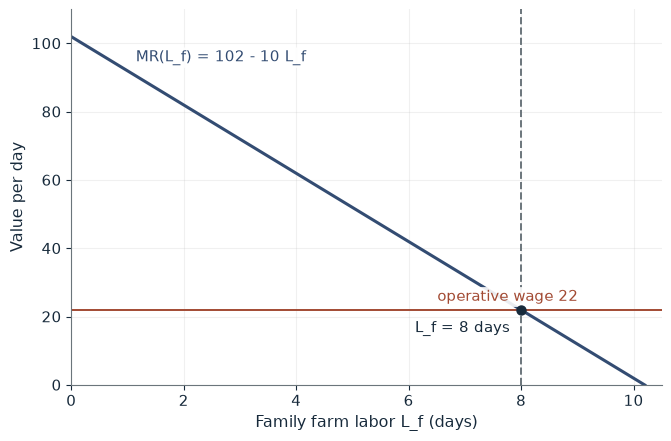

Labor market           Missing
Operative wage         22
Farm labor L_f (days)  8

Worked steps:
  1. Operative wage = 22 (shadow)
  2. 102 - 10 L_f = 22, so L_f = (102 - 22) / 10 = 8

Hypothetical teaching values, not data from a real farm or market. Here with no labor market the household's shadow wage of 22 sets the margin: 102 - 10 L_f = 22 gives L_f = 8 days. Without a market, anything that changes the household's valuation of leisure changes farm labor.


In [2]:
show(farm_labor_picture(market='missing', ws=22))

Change one input, `ws`, and hold the others at the book's values:

In [3]:
sweep(farm_labor_picture, 'ws', [22, 32, 42], {'market': 'missing'}, ['Operative wage', 'Farm labor L_f (days)'])

ws | Operative wage | Farm labor L_f (days)
22 | 22 | 8
32 | 32 | 7
42 | 42 | 6


With the market missing, farm labor is 8 days at a shadow wage of 22 and 7 days at 32. With the market open it is 6 days whatever the shadow wage.

## 2. Von Thunen land-use rings: refrigeration and the vegetable ring

Hypothetical bid rents by distance d from the market.

$$R_v(d)=1{,}080-110d, \qquad R_g(d)=620-20d$$

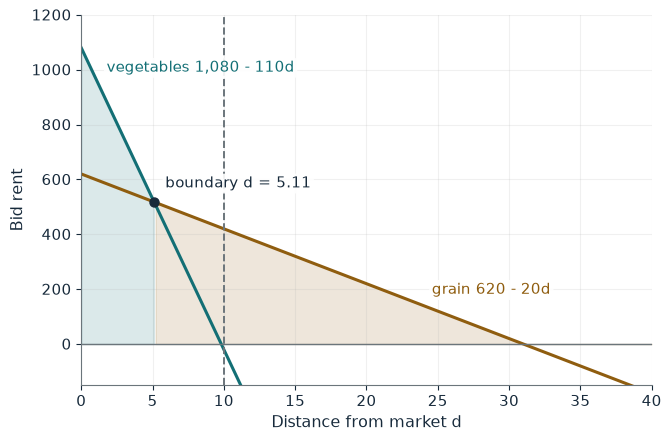

Boundary d               5.11
Grain outer margin       31.00
Vegetable bid at d = 10  -20
Grain bid at d = 10      420
Use at d = 10            Grain

Worked steps:
  1. 1,080 - 110d = 620 - 20d gives d = 460 / 90 = 5.11
  2. Grain margin: 620 - 20d = 0 gives d = 31.00
  3. At d = 10: vegetables 1,080 - 1,100 = -20; grain 620 - 200 = 420

Hypothetical teaching values, not data from a real farm or market. With a vegetable transport slope of 110 and a grain bid of 620 at the market, the bids cross at d = 460 / 90 = 5.11: vegetables inside, grain outside to d = 31.00. At distance 10 vegetables bid -20 against grain 420, so the land goes to grain.


In [4]:
show(rings_picture(tv=110, ig=620))

Change one input, `tv`, and hold the others at the book's values:

In [5]:
sweep(rings_picture, 'tv', [55, 80, 110], {'ig': 620}, ['Boundary d', 'Use at d = 10'])

tv | Boundary d | Use at d = 10
55 | 13.14 | Vegetables
80 | 7.67 | Grain
110 | 5.11 | Grain


The boundary is 460 / 90 = 5.11; refrigeration (slope 55) moves it to 13.14 and switches land at distance 10 from grain (420) to vegetables (530).

## 3. Stiglitz sharecropping tradeoff: insurance against effort

Hypothetical values: output 120 or 40 with low effort; high effort adds 48 at cost 27.

$$s\Delta Y=0.50(48)=24$$

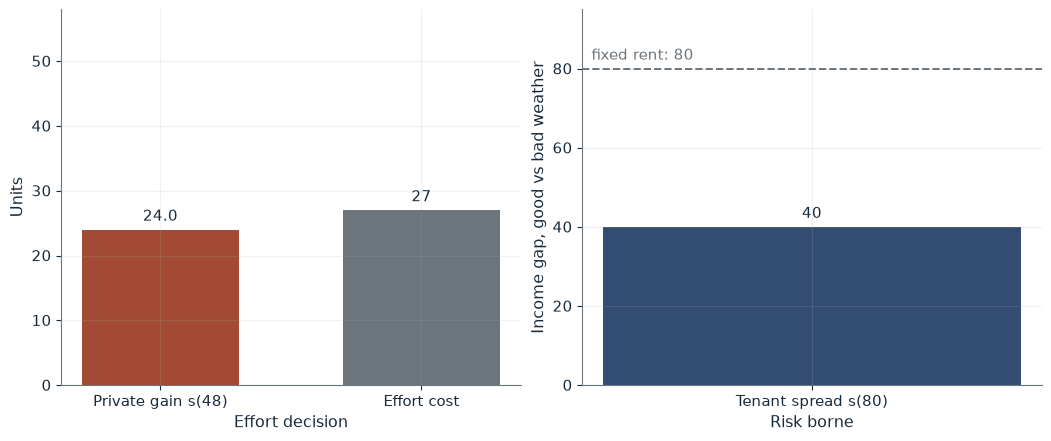

Private gain s x 48            24.0
Effort                         Low
Weather spread s x 80          40
Minimum share for high effort  0.562

Worked steps:
  1. Private gain = 0.50 x 48 = 24.0
  2. 24.0 < 27: low effort
  3. Spread = 0.50 x (120 - 40) = 40
  4. Minimum share = 27 / 48 = 0.562

Hypothetical teaching values, not data from a real farm or market. With share 0.50 the tenant keeps 0.50 x 48 = 24.0 of the extra output, less than the effort cost of 27, so effort is low. The tenant bears a weather spread of 40 against 80 under fixed rent: a larger share buys effort with risk.


In [6]:
show(share_picture(s=0.50, cost=27))

Change one input, `s`, and hold the others at the book's values:

In [7]:
sweep(share_picture, 's', [0.5, 0.65, 1.0], {'cost': 27}, ['Private gain s x 48', 'Effort', 'Weather spread s x 80'])

s | Private gain s x 48 | Effort | Weather spread s x 80
0.5 | 24.0 | Low | 40
0.65 | 31.2 | High | 52
1.0 | 48.0 | High | 80


A one-half share leaves a gain of 24 < 27, so effort is low, with a spread of 40. A 0.65 share gives 31.2 and high effort at a spread of 52; fixed rent gives 48 and 80.

## 4. Cobweb theorem: converging and exploding cycles

Hypothetical schedules: demand 108 - 2P_t and supply 24 + dP_(t-1).

$$a-bP_t=c+dP_{t-1}, \qquad P_t-P^*=-\frac{d}{b}(P_{t-1}-P^*)$$

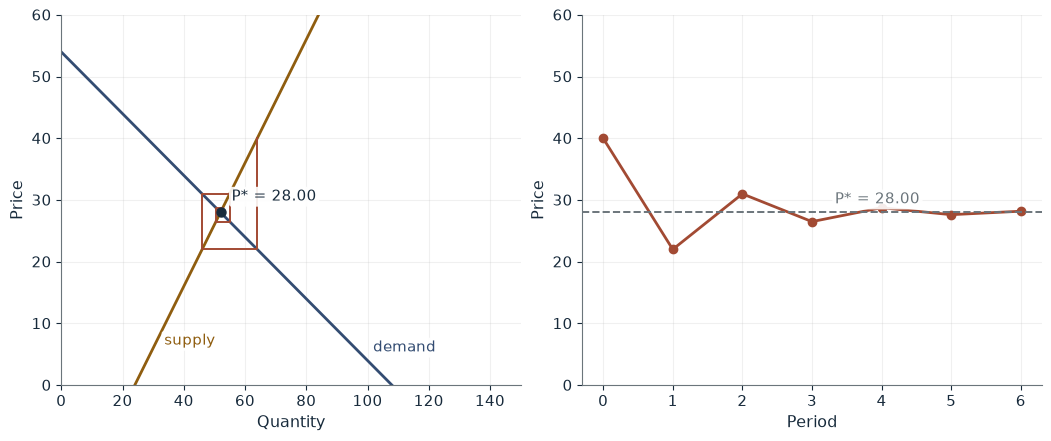

P*                    28.00
Deviation ratio -d/b  -0.50
First prices          22.00, 31.00, 26.50

Worked steps:
  1. P* = (108 - 24) / (2 + 1) = 28.00
  2. Supply = 24 + 1 x 40 = 64; P_1 = (108 - 64) / 2 = 22.00
  3. Supply = 24 + 1 x 22.00 = 46.00; P_2 = (108 - 46.00) / 2 = 31.00
  4. Ratio = -1 / 2 = -0.50: deviations shrink and price converges

Hypothetical teaching values, not data from a real farm or market. With supply 24 + 1P_(t-1) the stationary price is 28.00. Starting from 40, prices run 40.00, 22.00, 31.00, 26.50, 28.75, 27.62, 28.19. The deviation ratio is -1 / 2 = -0.50, so deviations shrink and price converges.


In [8]:
show(cobweb_picture(d=1, p0=40))

Change one input, `d`, and hold the others at the book's values:

In [9]:
sweep(cobweb_picture, 'd', [1, 2, 3], {'p0': 20}, ['P*', 'Deviation ratio -d/b', 'First prices'])

d | P* | Deviation ratio -d/b | First prices
1 | 28.00 | -0.50 | 32.00, 26.00, 29.00
2 | 21.00 | -1.00 | 22.00, 20.00, 22.00
3 | 16.80 | -1.50 | 12.00, 24.00, 6.00


With d = 1 the price path from 40 is 22, 31, 26.5, converging to 28. With d = 3 the stationary price is 16.8 and from 20 the deviations grow (12, 24, 6, 33) until the linear model breaks down.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

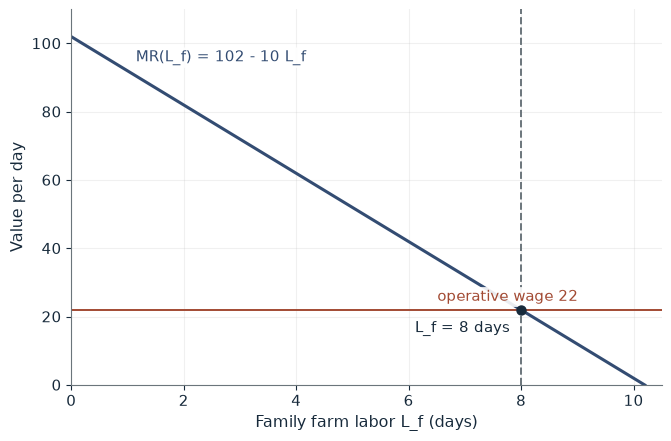

Labor market           Missing
Operative wage         22
Farm labor L_f (days)  8

Worked steps:
  1. Operative wage = 22 (shadow)
  2. 102 - 10 L_f = 22, so L_f = (102 - 22) / 10 = 8

Hypothetical teaching values, not data from a real farm or market. Here with no labor market the household's shadow wage of 22 sets the margin: 102 - 10 L_f = 22 gives L_f = 8 days. Without a market, anything that changes the household's valuation of leisure changes farm labor.


In [10]:
show(farm_labor_picture(market='missing', ws=22))

## Practice

**1.** With the market missing and a shadow wage of 32, how many days of family labor?

<details><summary>Answer</summary>

102 - 10 L = 32, so L = 7.

</details>

**2.** With a vegetable slope of 80 and grain bid 620, where is the boundary?

<details><summary>Answer</summary>

1,080 - 80d = 620 - 20d gives d = 460 / 60 = 7.67.

</details>

**3.** With d = 2 and starting price 40, what are P* and P_1?

<details><summary>Answer</summary>

P* = 84 / 4 = 21; supply 24 + 80 = 104, so P_1 = (108 - 104) / 2 = 2; the ratio -1 gives a constant oscillation.

</details>